# 03 · Models — Flight Price (Regression)
Part-1 models on the same data, preprocessing and 5 CV folds. Metric: R² on raw price. Every run is logged to `results/regression/experiments.csv`.

## Setup
Make `src/` importable and load the shared config (seed, paths).

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

# Make `src` importable: repo root locally, or an uploaded Kaggle dataset containing src/
for p in [Path.cwd(), *Path.cwd().parents, *(f.parent.parent for f in Path("/kaggle/input").glob("**/src/config.py"))]:
    if (p / "src" / "config.py").exists():
        sys.path.insert(0, str(p.resolve()))
        break

from src import config

Load the clean data.

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor

from src import evaluate
from src.regression import preprocess as pp
from src.regression.models import ClassInteractions, PerGroupRegressor

warnings.filterwarnings("ignore", message="Found unknown categories")
TASK = "regression"
FIG_DIR = config.results_dir(TASK) / "figures"
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

X, y, X_test, test_ids, sample_sub = pp.load_clean()
print("X", X.shape, "| X_test", X_test.shape)

X (15167, 10) | X_test (3898, 10)


Helper: run CV, log it and print the scores.

In [3]:
scores = {}

def run(name, model, params=None, notes=""):
    folds = evaluate.cross_validate(model, X, y, TASK, name, params=params, notes=notes)
    scores[name] = folds.mean()
    print(f"{name:28s} CV R² {folds.r2.mean():.4f} ± {folds.r2.std():.4f} | train R² {folds.train_r2.mean():.4f}"
          f" | RMSE ₹{folds.rmse.mean():,.0f}")
    return folds

## 1 · Linear regression (OLS)

In [4]:
ols = make_pipeline(pp.make_preprocessor(drop_first=True), LinearRegression())
_ = run("1_ols", ols, notes="plain least squares")

1_ols                        CV R² 0.8345 ± 0.0038 | train R² 0.8366 | RMSE ₹15,997


- CV R² 0.8345, train 0.8366: underfits.

OLS coefficients for airline and class.

In [5]:
ols.fit(X, y)
coef = pd.Series(ols[-1].coef_, index=ols[:-1].get_feature_names_out())
print(f"intercept: ₹{ols[-1].intercept_:,.0f}")
coef[coef.index.str.startswith(("airline_", "flight_class_"))].sort_values().map("₹{:,.0f}".format).to_frame("coefficient")

intercept: ₹74,379


,coefficient
airline_Oceanic Airlines,"₹-33,222"
flight_class_Economy,"₹-30,837"
airline_Wayfarer Aviation,"₹-29,046"
airline_Sandpiper Air,"₹-27,535"
airline_Vandelay Aviation,"₹-25,465"
airline_Wayne Enterprises Air,"₹21,542"
airline_infrequent_sklearn,"₹49,272"
airline_Virtucon,"₹51,511"
airline_Stark Aviation,"₹53,265"
airline_Nakatomi Airlines,"₹63,055"


## 2 · OLS on log(price)

In [6]:
_ = run("2_ols_log", evaluate.log_target(make_pipeline(pp.make_preprocessor(drop_first=True), LinearRegression())),
        notes="log target")

2_ols_log                    CV R² 0.8264 ± 0.0120 | train R² 0.8275 | RMSE ₹16,372


Mean out-of-fold prediction per class, raw vs log target.

In [7]:
oof = pd.DataFrame({
    "class": X.flight_class.to_numpy(), "true": y.to_numpy(),
    "ols": evaluate.oof_predict(make_pipeline(pp.make_preprocessor(drop_first=True), LinearRegression()), X, y, TASK),
    "ols_log": evaluate.oof_predict(evaluate.log_target(make_pipeline(pp.make_preprocessor(drop_first=True), LinearRegression())), X, y, TASK),
})
summary = oof.groupby("class")[["true", "ols", "ols_log"]].mean().round(0)
summary["ols_log − true"] = summary["ols_log"] - summary["true"]
display(summary)
print("negative predictions — ols:", (oof.ols < 0).sum(), "| ols_log:", (oof.ols_log < 0).sum())

,true,ols,ols_log,ols_log − true
class,,,,
Business,60408.0,60364.0,58304.0,-2104.0
Economy,8792.0,8795.0,8457.0,-335.0


negative predictions — ols: 172 | ols_log: 0


- Log target scores lower (0.8264) because it under-predicts expensive tickets, so we train on raw price.

## 3 · OLS + class interactions

In [8]:
_ = run("3_ols_class_interactions",
        make_pipeline(pp.make_preprocessor(drop_first=True), ClassInteractions(), LinearRegression()),
        notes="every feature x class indicator")

3_ols_class_interactions     CV R² 0.8805 ± 0.0051 | train R² 0.8826 | RMSE ₹13,593


- CV R² 0.8805 (+0.046 over OLS).

## 4 · Separate OLS per class

In [9]:
_ = run("4_ols_per_class", PerGroupRegressor(make_pipeline(pp.make_preprocessor(drop_first=True), LinearRegression())),
        notes="one OLS per flight_class")

4_ols_per_class              CV R² 0.8763 ± 0.0052 | train R² 0.8785 | RMSE ₹13,828


- CV R² 0.8763: the same idea as model 3.

## 5 · Polynomial features (degree 2) + OLS

In [10]:
_ = run("5_poly2_ols", make_pipeline(pp.make_preprocessor(drop_first=True), PolynomialFeatures(2, include_bias=False),
                                     LinearRegression()), notes="degree-2 polynomial features")

5_poly2_ols                  CV R² 0.9070 ± 0.0084 | train R² 0.9329 | RMSE ₹11,977


- CV R² 0.9070; train–CV gap grows to 0.026.

## 6 · Polynomial features + Ridge (tune α)

In [11]:
def ridge_poly(alpha):
    return make_pipeline(pp.make_preprocessor(), PolynomialFeatures(2, include_bias=False), Ridge(alpha=alpha))

ridge_table, ridge_best = evaluate.grid_search(ridge_poly, [{"alpha": a} for a in [0.1, 1, 10, 100]],
                                               X, y, TASK, "6_poly2_ridge", notes="degree-2 polynomial + L2")
scores["6_poly2_ridge"] = ridge_table.iloc[0]
display(ridge_table.round(4))
print("best:", ridge_best)

,alpha,r2_mean,r2_std,train_r2
0,10.0,0.9174,0.0060,0.9291
1,1.0,0.9163,0.0060,0.9324
2,0.1,0.9134,0.0054,0.9328
3,100.0,0.9053,0.0038,0.9134


best: {'alpha': 10}


- Best α = 10: CV R² 0.9174.

## 7 · Lasso on class-interaction features (tune α)

In [12]:
def lasso_inter(alpha):
    return make_pipeline(pp.make_preprocessor(), ClassInteractions(), Lasso(alpha=alpha, max_iter=50_000))

lasso_table, lasso_best = evaluate.grid_search(lasso_inter, [{"alpha": a} for a in [10, 100, 1000]],
                                               X, y, TASK, "7_lasso_class_interactions", notes="class interactions + L1")
lasso_table["features kept"] = [int((lasso_inter(a).fit(X, y)[-1].coef_ != 0).sum()) for a in lasso_table.alpha]
lasso_table["features total"] = len(lasso_inter(10).fit(X, y)[-1].coef_)
scores["7_lasso_class_interactions"] = lasso_table.iloc[0]
lasso_table.round(4)

,alpha,r2_mean,r2_std,train_r2,features kept,features total
0,10,0.8804,0.0053,0.8824,58,78
1,100,0.8732,0.0069,0.8749,35,78
2,1000,0.7579,0.0022,0.7584,11,78


- Best α = 10: CV R² 0.8804 with 58 of 78 features.

Features dropped by Lasso at α = 100.

In [13]:
lasso100 = lasso_inter(100).fit(X, y)
coef = pd.Series(lasso100[-1].coef_, index=lasso100[:-1].get_feature_names_out())
dropped = coef[coef == 0].index
print(f"dropped {len(dropped)} of {len(coef)} features:")
print("\n".join(sorted(dropped)))

dropped 43 of 78 features:
airline_Ajira Airways
airline_Sandpiper Air x flight_class_Business
airline_Vandelay Aviation
airline_Vandelay Aviation x flight_class_Business
airline_Virtucon x flight_class_Business
airline_Wayne Enterprises Air
airline_Wayne Enterprises Air x flight_class_Business
airline_infrequent_sklearn
arrival_time_Afternoon
arrival_time_Early_Morning
arrival_time_Early_Morning x flight_class_Business
arrival_time_Evening
arrival_time_Evening x flight_class_Business
arrival_time_Late_Night
arrival_time_Morning
arrival_time_Morning x flight_class_Business
arrival_time_Night
arrival_time_Night x flight_class_Business
days_left
departure_time_Afternoon
departure_time_Early_Morning
departure_time_Evening
departure_time_Evening x flight_class_Business
departure_time_Late_Night
departure_time_Morning
departure_time_Morning x flight_class_Business
departure_time_Night
destination_city_Gotham
destination_city_Gotham x flight_class_Business
destination_city_Los Santos
destina

- Lasso drops time slots, `days_left` and `stops`.

## 8 · Decision tree (fully grown)

In [14]:
tree_full = make_pipeline(pp.make_preprocessor(scale=False), DecisionTreeRegressor(random_state=config.SEED))
_ = run("8_tree_full", tree_full, notes="unpruned")
tree_full.fit(X, y)
print(f"depth {tree_full[-1].get_depth()}, leaves {tree_full[-1].get_n_leaves():,} "
      f"(≈ {len(X) / tree_full[-1].get_n_leaves():.1f} training rows per leaf)")

8_tree_full                  CV R² 0.8634 ± 0.0074 | train R² 0.9993 | RMSE ₹14,533
depth 41, leaves 8,695 (≈ 1.7 training rows per leaf)


- Train R² 0.9993 vs CV 0.8634: overfits.

## 9 · Pruned decision tree (tune depth, leaf size, ccp_alpha)

In [15]:
def tree(max_depth, min_samples_leaf, ccp_alpha):
    return make_pipeline(pp.make_preprocessor(scale=False),
                         DecisionTreeRegressor(max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                               ccp_alpha=ccp_alpha, random_state=config.SEED))

grid = [{"max_depth": d, "min_samples_leaf": l, "ccp_alpha": a}
        for d in [8, 12, None] for l in [1, 5, 10, 20] for a in [0.0, 1e5, 1e6]]
tree_table, tree_best = evaluate.grid_search(tree, grid, X, y, TASK, "9_tree_pruned", notes="max_depth/min_samples_leaf/ccp_alpha")
scores["9_tree_pruned"] = tree_table.iloc[0]
display(tree_table.head(10).round(4))
print("best:", tree_best)

,max_depth,min_samples_leaf,ccp_alpha,r2_mean,r2_std,train_r2
0,12.0,5,0.0,0.9073,0.0097,0.9390
1,12.0,5,100000.0,0.9052,0.0101,0.9351
2,12.0,10,0.0,0.9048,0.0123,0.9289
3,NaN,10,0.0,0.9041,0.0116,0.9350
4,12.0,10,100000.0,0.9033,0.0115,0.9258
5,NaN,20,0.0,0.9032,0.0127,0.9203
6,NaN,5,0.0,0.9030,0.0114,0.9530
7,NaN,10,100000.0,0.9028,0.0108,0.9306
8,12.0,20,0.0,0.9019,0.0126,0.9183
9,NaN,20,100000.0,0.9014,0.0131,0.9178


best: {'max_depth': 12, 'min_samples_leaf': 5, 'ccp_alpha': 0.0}


- Best: depth 12, leaf ≥ 5: CV R² 0.9073.

Size and top features of the pruned tree.

In [16]:
best_tree = tree(**tree_best).fit(X, y)
t = best_tree[-1]
print(f"depth {t.get_depth()}, leaves {t.get_n_leaves():,}")
imp = pd.Series(t.feature_importances_, index=best_tree[:-1].get_feature_names_out()).sort_values(ascending=False)
imp.head(5).round(3).to_frame("importance")

depth 12, leaves 563


,importance
duration,0.686
flight_class_Business,0.123
flight_class_Economy,0.064
airline_Ajira Airways,0.033
airline_Wayfarer Aviation,0.026


## Comparison

,model,params,r2_mean,r2_std,train_r2_mean,rmse_mean,public_lb
0,6_poly2_ridge,"{""alpha"": 10}",0.9174,0.0060,0.9291,11291.5755,0.9445
1,9_tree_pruned,"{""max_depth"": 12, ""min_samples_leaf"": 5, ""ccp_...",0.9073,0.0097,0.9390,11957.4912,NaN
2,5_poly2_ols,{},0.9070,0.0084,0.9329,11977.3999,NaN
3,3_ols_class_interactions,{},0.8805,0.0051,0.8826,13592.6963,NaN
4,7_lasso_class_interactions,"{""alpha"": 10}",0.8804,0.0053,0.8824,13600.9001,NaN
5,4_ols_per_class,{},0.8763,0.0052,0.8785,13827.8681,NaN
6,8_tree_full,{},0.8634,0.0074,0.9993,14532.7939,NaN
7,1_ols,{},0.8345,0.0038,0.8366,15996.6330,NaN
8,2_ols_log,{},0.8264,0.0120,0.8275,16372.3849,NaN


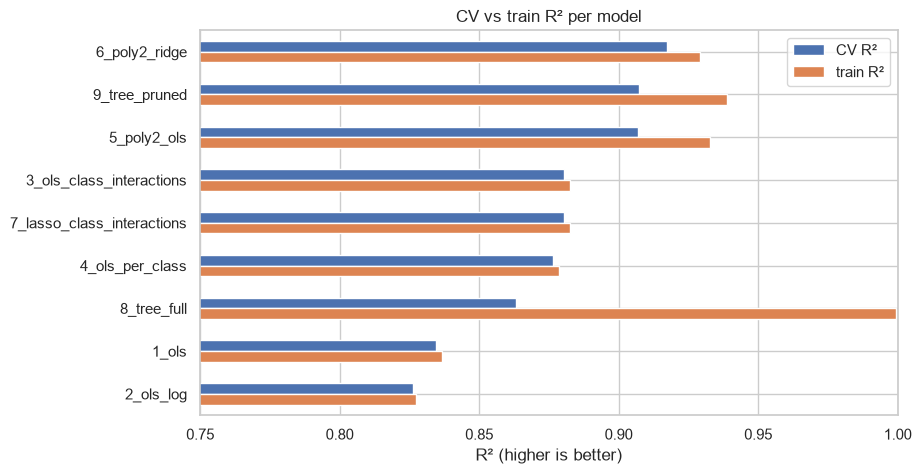

In [17]:
log = pd.read_csv(config.results_dir(TASK) / "experiments.csv")
log = log[log.model.isin(scores)]  # models from this notebook only
table = (log[["model", "params", "r2_mean", "r2_std", "train_r2_mean", "rmse_mean", "public_lb"]]
         .sort_values("r2_mean", ascending=False).reset_index(drop=True))
display(table.round(4))

plot = table.dropna(subset=["train_r2_mean"]).set_index("model")[["r2_mean", "train_r2_mean"]]
ax = plot.rename(columns={"r2_mean": "CV R²", "train_r2_mean": "train R²"}).plot.barh(figsize=(9, 5))
ax.set(xlim=(0.75, 1.0), xlabel="R² (higher is better)", ylabel="", title="CV vs train R² per model")
ax.invert_yaxis()
plt.savefig(FIG_DIR / "models_r2.png", dpi=120, bbox_inches="tight")
plt.show()

## Submission (best model of this notebook)

In [18]:
best_name = table.model.iloc[0]
best_model = {"6_poly2_ridge": lambda: ridge_poly(**ridge_best),
              "9_tree_pruned": lambda: tree(**tree_best)}[best_name]()
path, sub = evaluate.make_submission(best_model, X, y, X_test, test_ids, sample_sub, TASK, best_name, date="2026-10-11")
print("best model:", best_name, "| saved:", path.name)
print(sub["price"].describe().round(0).to_string())

best model: 6_poly2_ridge | saved: 2026-10-11_6_poly2_ridge.csv
count      3898.0
mean      29641.0
std       38100.0
min       -7591.0
25%        7635.0
50%       11332.0
75%       37127.0
max      259660.0


- Submitted `6_poly2_ridge`: public score 0.94450.